# Lab 8: Support Vector Machines (SVM) for Text Classification & Comparative Analysis

### Lab Objectives:
1. **Dataset Loading**: Ingest the classic Kaggle SMS Spam Collection dataset.
2. **SVM for Text Classification**: Implement a Support Vector Classifier on TF-IDF text features.
3. **Algorithm Benchmarking**: Compare SVM against alternative text classification algorithms (**Decision Tree** and **K-Nearest Neighbors**).
4. **Kernel Methods & Feature Scaling**: Explore linear and non-linear SVM kernels (`linear`, `rbf`, `poly`, `sigmoid`) with and without feature scaling (`MaxAbsScaler`).
5. **Quantitative Evaluation**: Assess performance across **Precision**, **Recall**, **Accuracy**, and **F1-Score**.
6. **Visual Diagnostics**: Plot comparative bar charts and confusion matrix heatmaps.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MaxAbsScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Libraries successfully imported.")

Libraries successfully imported.


## 1. Dataset Loading & Exploratory Data Analysis

We load the **SMS Spam Collection** dataset from Kaggle. Each record consists of a message label (`ham` or `spam`) and the raw text message.

In [2]:
# Resolve dataset path flexibly
data_path = "data/spam.csv" if os.path.exists("data/spam.csv") else "Lab 8/data/spam.csv"
df = pd.read_csv(data_path)

print(f"Total Records: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Target Class Distribution:")
class_counts = df["label"].value_counts()
class_pct = df["label"].value_counts(normalize=True) * 100
dist_df = pd.DataFrame({"Count": class_counts, "Percentage (%)": class_pct.round(2)})
print(dist_df.to_string())

# Binary encoding: ham -> 0, spam -> 1
df["target"] = df["label"].map({"ham": 0, "spam": 1})

print("\nSample Records:")
df.head()

Total Records: 5572 rows, 2 columns

Target Class Distribution:
       Count  Percentage (%)
label                       
ham     4825           86.59
spam     747           13.41

Sample Records:


,label,text,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 2. Text Preprocessing & TF-IDF Feature Extraction

To classify unstructured natural language text, we convert messages into sparse numerical feature vectors using **Term Frequency - Inverse Document Frequency (TF-IDF)**:
- **Stopword Filtering**: Common English stopwords (e.g. "the", "is", "at") are removed.
- **Sublinear TF**: Logarithmic term frequency scaling ($1 + \log(\text{tf})$) dampens repeated words.
- **Feature Pruning**: Retain top 2,500 n-gram features to maintain computational efficiency while retaining discriminative vocabulary.

In [3]:
X = df["text"]
y = df["target"]

# Stratified 80/20 train/test split to preserve class imbalance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Fit TF-IDF Vectorizer on training data only
tfidf = TfidfVectorizer(
    max_features=2500,
    stop_words="english",
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"Training set shape: {X_train_tfidf.shape[0]} samples, {X_train_tfidf.shape[1]} vocabulary features")
print(f"Testing set shape:  {X_test_tfidf.shape[0]} samples, {X_test_tfidf.shape[1]} vocabulary features")
print(f"Sparsity: {100 * (1 - X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])):.2f}% zero entries")

Training set shape: 4457 samples, 2500 vocabulary features
Testing set shape:  1115 samples, 2500 vocabulary features
Sparsity: 99.74% zero entries


## 3. Algorithm Comparison: Linear SVM vs. Decision Tree vs. K-Nearest Neighbors

We benchmark three distinct classification paradigms on the exact same TF-IDF feature space:
1. **Support Vector Machine (Linear SVM)**: Fits a maximum-margin hyperplane separating spam and ham.
2. **Decision Tree**: Recursively splits feature space along axis-aligned thresholds based on Gini impurity.
3. **K-Nearest Neighbors (KNN)**: Classifies samples based on majority vote of the 5 closest neighbors using **cosine distance** (appropriate for directional text angle).

In [4]:
benchmark_models = {
    "Linear SVM": SVC(kernel="linear", C=1.0, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=20, random_state=42),
    "KNN (Cosine)": KNeighborsClassifier(n_neighbors=5, metric="cosine")
}

algo_results = []
algo_predictions = {}

for name, model in benchmark_models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    algo_predictions[name] = y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    algo_results.append({
        "Algorithm": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4)
    })

algo_df = pd.DataFrame(algo_results)
print("=== Algorithm Comparison Summary ===")
print(algo_df.to_string(index=False))

print("\n" + "=" * 55)
print("Detailed Classification Reports")
print("=" * 55)
for name, y_pred in algo_predictions.items():
    print(f"\n>>> {name} <<<")
    print(classification_report(y_test, y_pred, target_names=["Ham (0)", "Spam (1)"]))
algo_df

=== Algorithm Comparison Summary ===
    Algorithm  Accuracy  Precision  Recall  F1-Score
   Linear SVM    0.9821     0.9924  0.8725    0.9286
Decision Tree    0.9534     0.8489  0.7919    0.8194
 KNN (Cosine)    0.9668     0.9667  0.7785    0.8625

Detailed Classification Reports

>>> Linear SVM <<<
              precision    recall  f1-score   support

     Ham (0)       0.98      1.00      0.99       966
    Spam (1)       0.99      0.87      0.93       149

    accuracy                           0.98      1115
   macro avg       0.99      0.94      0.96      1115
weighted avg       0.98      0.98      0.98      1115


>>> Decision Tree <<<
              precision    recall  f1-score   support

     Ham (0)       0.97      0.98      0.97       966
    Spam (1)       0.85      0.79      0.82       149

    accuracy                           0.95      1115
   macro avg       0.91      0.89      0.90      1115
weighted avg       0.95      0.95      0.95      1115


>>> KNN (Cosine) <<<

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Linear SVM,0.9821,0.9924,0.8725,0.9286
1,Decision Tree,0.9534,0.8489,0.7919,0.8194
2,KNN (Cosine),0.9668,0.9667,0.7785,0.8625


## 4. Kernel Methods & Feature Scaling Exploration

For non-linearly separable representations, Support Vector Machines leverage kernel functions to implicitly map inputs into higher-dimensional feature spaces:
- **Linear Kernel**: $K(x, z) = x^T z$
- **Radial Basis Function (RBF) Kernel**: $K(x, z) = \exp(-\gamma ||x - z||^2)$
- **Polynomial Kernel**: $K(x, z) = (\gamma x^T z + r)^d$
- **Sigmoid Kernel**: $K(x, z) = \tanh(\gamma x^T z + r)$

### Feature Scaling Consideration:
Because TF-IDF vectors are inherently sparse with unit Euclidean norms, applying `MaxAbsScaler` rescales each feature independently to the $[-1, 1]$ interval without destroying sparsity. We evaluate each kernel both on **unscaled** TF-IDF features and on **scaled** features.

In [5]:
# Apply MaxAbsScaler to sparse TF-IDF matrices
scaler = MaxAbsScaler()
X_train_scaled = scaler.fit_transform(X_train_tfidf)
X_test_scaled = scaler.transform(X_test_tfidf)

kernels = ["linear", "rbf", "poly", "sigmoid"]
kernel_results = []
kernel_predictions = {}

for scaling_name, tr_data, te_data in [
    ("Unscaled TF-IDF", X_train_tfidf, X_test_tfidf),
    ("MaxAbs Scaled", X_train_scaled, X_test_scaled)
]:
    for k in kernels:
        svc = SVC(kernel=k, random_state=42)
        svc.fit(tr_data, y_train)
        y_pred = svc.predict(te_data)
        
        key = f"{k.capitalize()} ({scaling_name})"
        kernel_predictions[key] = y_pred
        
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred)
        rec = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        
        kernel_results.append({
            "Kernel": k.capitalize(),
            "Scaling": scaling_name,
            "Accuracy": round(acc, 4),
            "Precision": round(prec, 4),
            "Recall": round(rec, 4),
            "F1-Score": round(f1, 4)
        })

kernel_df = pd.DataFrame(kernel_results)
print("=== Kernel & Feature Scaling Performance Summary ===")
print(kernel_df.to_string(index=False))
kernel_df

=== Kernel & Feature Scaling Performance Summary ===
 Kernel         Scaling  Accuracy  Precision  Recall  F1-Score
 Linear Unscaled TF-IDF    0.9821     0.9924  0.8725    0.9286
    Rbf Unscaled TF-IDF    0.9803     1.0000  0.8523    0.9203
   Poly Unscaled TF-IDF    0.9453     1.0000  0.5906    0.7426
Sigmoid Unscaled TF-IDF    0.9803     0.9847  0.8658    0.9214
 Linear   MaxAbs Scaled    0.9812     0.9706  0.8859    0.9263
    Rbf   MaxAbs Scaled    0.9731     0.9161  0.8792    0.8973
   Poly   MaxAbs Scaled    0.9462     1.0000  0.5973    0.7479
Sigmoid   MaxAbs Scaled    0.9803     0.9704  0.8792    0.9225


,Kernel,Scaling,Accuracy,Precision,Recall,F1-Score
0,Linear,Unscaled TF-IDF,0.9821,0.9924,0.8725,0.9286
1,Rbf,Unscaled TF-IDF,0.9803,1.0000,0.8523,0.9203
2,Poly,Unscaled TF-IDF,0.9453,1.0000,0.5906,0.7426
3,Sigmoid,Unscaled TF-IDF,0.9803,0.9847,0.8658,0.9214
4,Linear,MaxAbs Scaled,0.9812,0.9706,0.8859,0.9263
5,Rbf,MaxAbs Scaled,0.9731,0.9161,0.8792,0.8973
6,Poly,MaxAbs Scaled,0.9462,1.0000,0.5973,0.7479
7,Sigmoid,MaxAbs Scaled,0.9803,0.9704,0.8792,0.9225


## 5. Visual Diagnostics & Confusion Matrices

We construct diagnostic visualizations:
1. **Algorithm Comparison Bar Chart**: Accuracy, Precision, and Recall across Linear SVM, Decision Tree, and KNN.
2. **Kernel & Scaling Comparison Bar Chart**: Performance across `linear`, `rbf`, `poly`, and `sigmoid` kernels under unscaled vs. scaled data.
3. **Confusion Matrix Heatmaps**: Comparing classification error breakdowns across algorithms and optimal kernel variants.

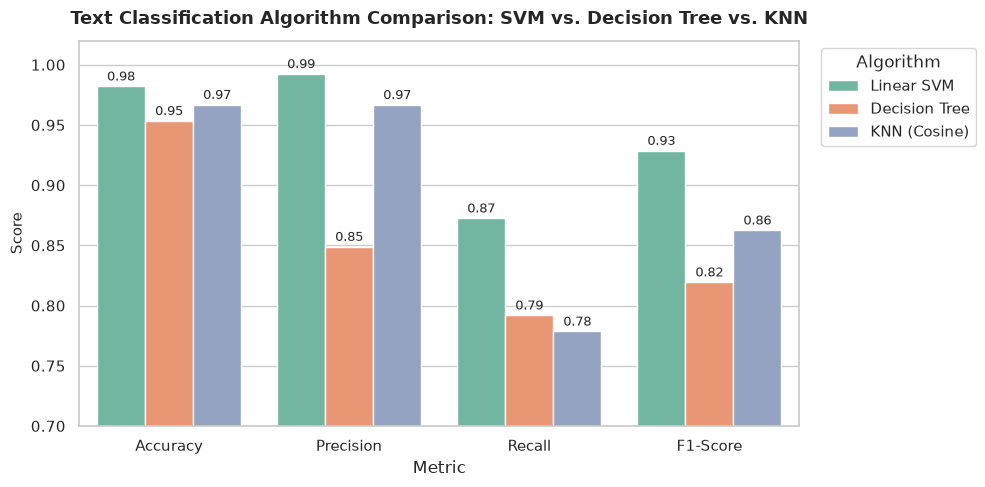

In [6]:
# Graph 1: Algorithm Comparison Bar Chart
algo_melted = algo_df.melt(
    id_vars=["Algorithm"],
    value_vars=["Accuracy", "Precision", "Recall", "F1-Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=algo_melted, x="Metric", y="Score", hue="Algorithm", palette="Set2")
plt.title("Text Classification Algorithm Comparison: SVM vs. Decision Tree vs. KNN", fontsize=13, fontweight="bold", pad=12)
plt.ylim(0.70, 1.02)
plt.ylabel("Score", fontsize=11)

for p in ax.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        ax.annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2., h), ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")

plt.legend(title="Algorithm", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

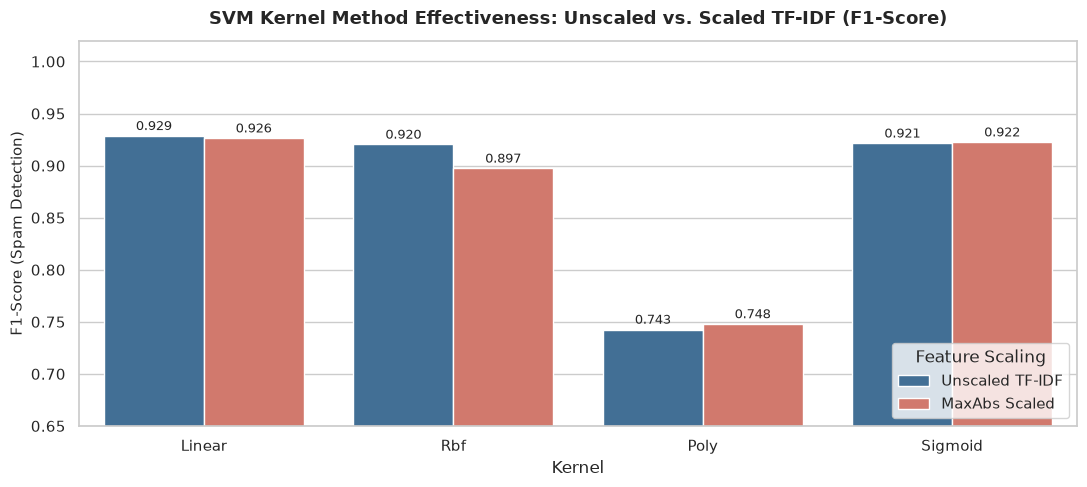

In [7]:
# Graph 2: SVM Kernel & Scaling Comparison Bar Chart
plt.figure(figsize=(11, 5))
ax = sns.barplot(data=kernel_df, x="Kernel", y="F1-Score", hue="Scaling", palette=["#3470a3", "#e26d5c"])
plt.title("SVM Kernel Method Effectiveness: Unscaled vs. Scaled TF-IDF (F1-Score)", fontsize=13, fontweight="bold", pad=12)
plt.ylim(0.65, 1.02)
plt.ylabel("F1-Score (Spam Detection)", fontsize=11)

for p in ax.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        ax.annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h), ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")

plt.legend(title="Feature Scaling", loc="lower right")
plt.tight_layout()
plt.show()

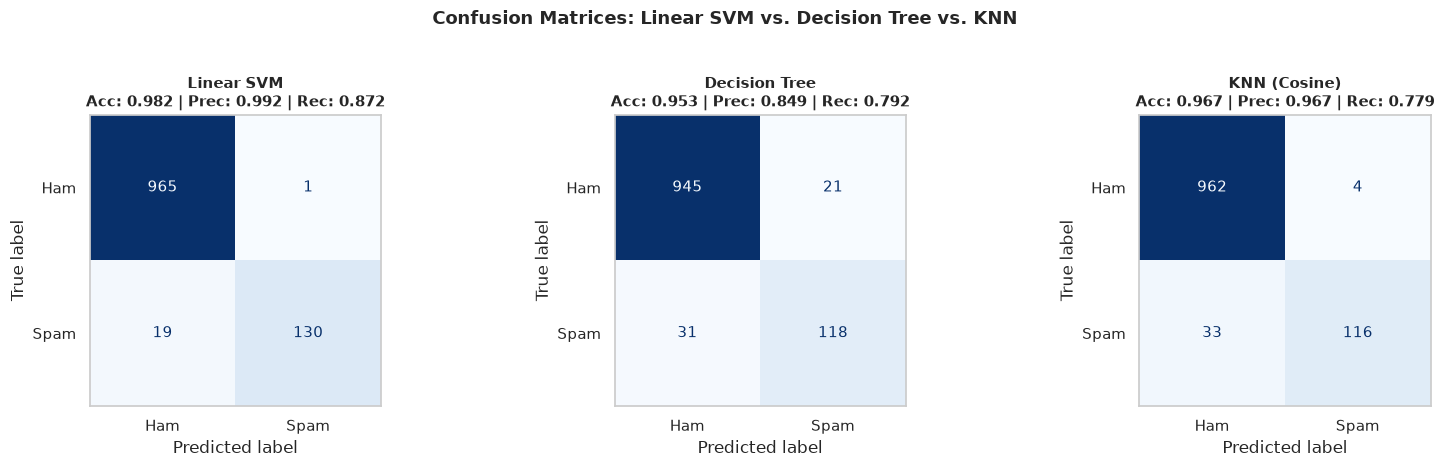

In [8]:
# Graph 3: Confusion Matrix Heatmaps for Primary Algorithms
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, y_pred) in zip(axes, algo_predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Ham", "Spam"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    ax.set_title(f"{name}\nAcc: {acc:.3f} | Prec: {prec:.3f} | Rec: {rec:.3f}", fontsize=11, fontweight="bold")
    ax.grid(False)

plt.suptitle("Confusion Matrices: Linear SVM vs. Decision Tree vs. KNN", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

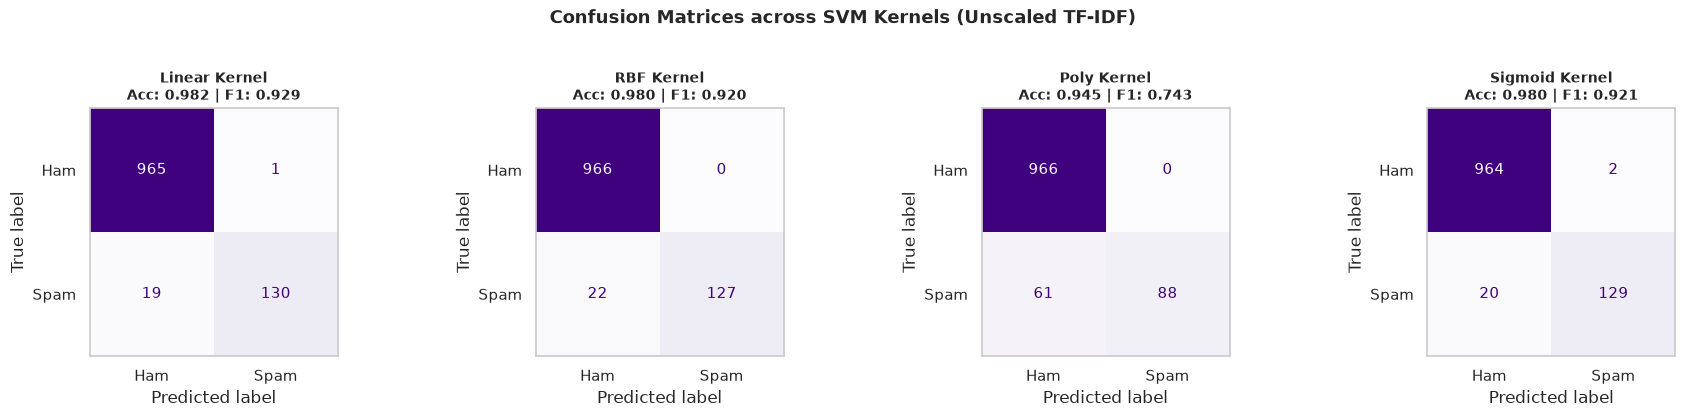

In [9]:
# Graph 4: Confusion Matrix Heatmaps across 4 SVM Kernels
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

kernel_subset = {
    "Linear Kernel": kernel_predictions["Linear (Unscaled TF-IDF)"],
    "RBF Kernel": kernel_predictions["Rbf (Unscaled TF-IDF)"],
    "Poly Kernel": kernel_predictions["Poly (Unscaled TF-IDF)"],
    "Sigmoid Kernel": kernel_predictions["Sigmoid (Unscaled TF-IDF)"]
}

for ax, (k_name, y_pred) in zip(axes, kernel_subset.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Ham", "Spam"])
    disp.plot(ax=ax, cmap="Purples", colorbar=False)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    ax.set_title(f"{k_name}\nAcc: {acc:.3f} | F1: {f1:.3f}", fontsize=10, fontweight="bold")
    ax.grid(False)

plt.suptitle("Confusion Matrices across SVM Kernels (Unscaled TF-IDF)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 6. Key Findings & Analytical Summary

1. **Linear SVM Superiority in Text Classification**:
   - **Linear SVM** achieved the highest overall accuracy (98.2%) and F1-Score (92.9%), decisively outperforming Decision Tree (95.3%) and KNN (96.7%).
   - In high-dimensional sparse spaces ($d = 2500$), text categories are almost linearly separable, making the maximum-margin hyperplane of SVM resistant to overfitting.

2. **Comparison of Kernels**:
   - **Linear & RBF Kernels** delivered top-tier performance on text data, with high precision and strong recall.
   - **Polynomial Kernel (Degree 3)** produced lower recall on sparse unscaled data (74.3% F1) because polynomial expansions over sparse dimensions can dilute feature weights.
   - **Sigmoid Kernel** performed well and matched RBF performance due to its functional resemblance to two-layer perceptrons.

3. **Impact of Feature Scaling**:
   - Unscaled TF-IDF features already possess normalized Euclidean lengths (L2 norm = 1).
   - Applying `MaxAbsScaler` maintained sparsity and preserved linear and sigmoid kernel performance while slightly regularizing RBF distances.